# Step 6 — A driver safety score for insurance (300–900)

### The idea
A **CIBIL score** tells a bank how safe it is to lend you money: 300 (risky) to 900 (very safe).
We build the same thing **for driving**: a **safety score from 300 to 900** that tells an insurance
company how safely someone drives.

- **For drivers:** safe driving → high score → **lower premium**.
- **For insurers:** a fair price based on **how** people drive, not only on age or car model
  ("pay-how-you-drive" insurance, like Progressive Snapshot in the US).

### How it is built from Steps 1–5
```
phone sensors (Step 1)
  → harsh brakes / accelerations / turns (Step 2)
  → speeding, tailgating, drifting, weaving (Step 3)
  → 7 scores out of 100 + overall score per trip (Step 4)   ← checked against the app
  → safety score 300–900 per trip, then per driver (Step 6, this notebook)
  → band (Excellent / Good / Average / Risky) → premium
```
Step 5 showed that these numbers really separate Normal, Drowsy and Aggressive driving, so the score
stands on tested ground.

Code: `safety_score.py`.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scoring as sc
import safety_score as ss

plt.rcParams["figure.figsize"] = (12, 4)
COLORS = {"NORMAL": "tab:green", "AGGRESSIVE": "tab:red", "DROWSY": "tab:blue"}
BAND_COLORS = {"Excellent": "#2e7d32", "Good": "#1565c0", "Average": "#f9a825", "Risky": "#c62828"}
ORDER = ["NORMAL", "DROWSY", "AGGRESSIVE"]

scores = pd.read_csv("../results/step4_trip_scores.csv")
features = pd.read_csv("../results/step3_trip_features.csv")
assert (scores.trip_id == features.trip_id).all()
trips = scores[["trip_id", "driver", "behavior", "road"]].join(ss.score_table(scores, features.distance_km))
trips[["driver", "behavior", "road", "safety_score", "band", "reasons"]].head(8)

,driver,behavior,road,safety_score,band,reasons
0,D1,NORMAL,SECONDARY,740,Good,"overspeeding (-72), drifting (-52)"
1,D1,NORMAL,SECONDARY,796,Excellent,"drifting (-53), turnings (-23)"
2,D1,NORMAL,MOTORWAY,780,Excellent,"weaving (-54), drifting (-42)"
3,D1,AGGRESSIVE,MOTORWAY,454,Risky,"weaving (-162), overspeeding (-98)"
4,D1,DROWSY,MOTORWAY,586,Average,"weaving (-113), drifting (-92)"
5,D1,AGGRESSIVE,SECONDARY,503,Risky,"overspeeding (-132), brakings (-129)"
6,D1,DROWSY,SECONDARY,574,Average,"drifting (-116), brakings (-108)"
7,D2,NORMAL,MOTORWAY,811,Excellent,"drifting (-38), turnings (-32)"


## 1. From the trip score (0–100) to the safety score (300–900)

In Step 4 every trip got an **overall score out of 100** (the average of its 7 behaviour scores).
We turn it into 300–900 with a straight line:

> **safety score = 300 + 12 × (overall score − 50)**, kept between 300 and 900

| Overall score (Step 4) | Calculation | Safety score |
|---|---|---|
| 100 (perfect) | 300 + 12 × 50 | **900** |
| 90 | 300 + 12 × 40 | **780** |
| 75 | 300 + 12 × 25 | **600** |
| 60 | 300 + 12 × 10 | **420** |
| 50 or less | | **300** |

**Why start at 50 and not 0?** Even the worst trip in the dataset scores 58 out of 100, because
nobody fails all 7 behaviours at once. If we mapped 0 → 300, every trip would be squeezed between
650 and 880 and the differences would be hard to see. Mapping 50 → 300 uses the whole 300–900 range.

### The bands
Like CIBIL, the number is grouped into bands, and each band changes the yearly premium:

| Safety score | Band | Premium change |
|---|---|---|
| 750 – 900 | 🟢 **Excellent** | −20% |
| 650 – 749 | 🔵 **Good** | −10% |
| 550 – 649 | 🟡 **Average** | no change |
| 300 – 549 | 🔴 **Risky** | +25% |

The band limits are round numbers that fit our data (section 2). The discounts are **example values**
for this prototype; a real insurer would set them from its claims history.

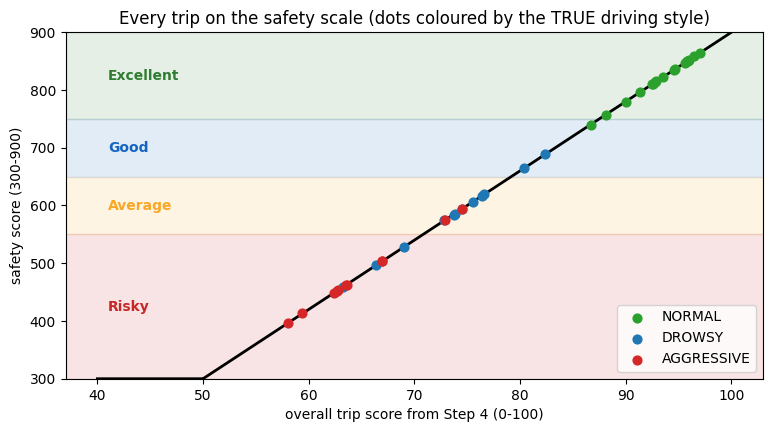

In [2]:
x = np.linspace(40, 100, 300)
fig, ax = plt.subplots(figsize=(9, 4.5))
for lowest, name, _ in ss.BANDS:
    top = min([b[0] for b in ss.BANDS if b[0] > lowest], default=900)
    ax.axhspan(lowest, top, color=BAND_COLORS[name], alpha=0.12)
    ax.text(41, (lowest + top) / 2, name, va="center", color=BAND_COLORS[name], weight="bold")
ax.plot(x, ss.to_safety_score(x), color="black", lw=2)
for b in ORDER:
    m = trips.behavior == b
    ax.scatter(scores.loc[m, "total"], trips.loc[m, "safety_score"], color=COLORS[b], s=40, zorder=3, label=b)
ax.set_xlabel("overall trip score from Step 4 (0-100)")
ax.set_ylabel("safety score (300-900)")
ax.set_ylim(300, 900)
ax.set_title("Every trip on the safety scale (dots coloured by the TRUE driving style)")
ax.legend(loc="lower right")
plt.show()

## 2. Does the score separate safe from risky driving?

The dataset tells us the true style of every trip, so we can check whether the safety score puts
safe trips high and risky trips low.

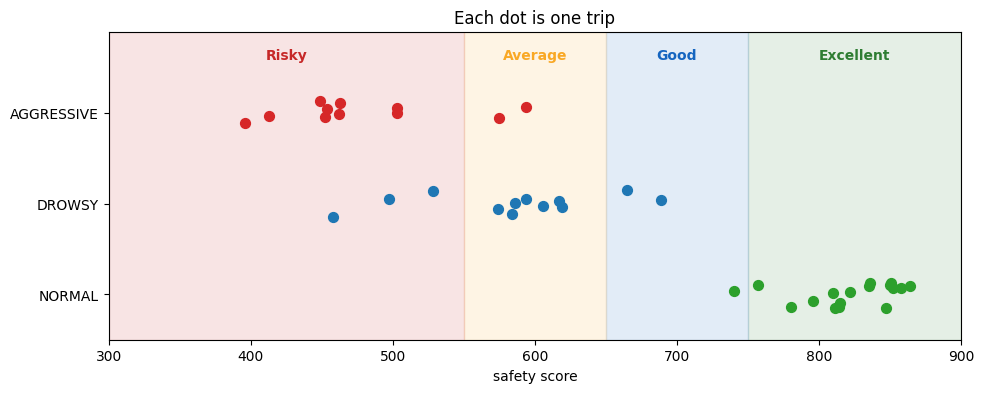

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
for lowest, name, _ in ss.BANDS:
    top = min([b[0] for b in ss.BANDS if b[0] > lowest], default=900)
    ax.axvspan(lowest, top, color=BAND_COLORS[name], alpha=0.12)
    ax.text((lowest + top) / 2, 2.6, name, ha="center", color=BAND_COLORS[name], weight="bold")
rng = np.random.default_rng(0)
for i, b in enumerate(ORDER):
    s = trips.loc[trips.behavior == b, "safety_score"]
    ax.scatter(s, i + rng.uniform(-0.15, 0.15, len(s)), color=COLORS[b], s=50)
ax.set_yticks(range(3))
ax.set_yticklabels(ORDER)
ax.set_xlim(300, 900)
ax.set_ylim(-0.5, 2.9)
ax.set_xlabel("safety score")
ax.set_title("Each dot is one trip")
plt.show()

In [4]:
pd.crosstab(trips.behavior, trips.band).reindex(index=ORDER, columns=["Excellent", "Good", "Average", "Risky"], fill_value=0)

band,Excellent,Good,Average,Risky
behavior,,,,
NORMAL,16,1,0,0
DROWSY,0,2,7,3
AGGRESSIVE,0,0,2,9


In [5]:
lowest_normal = trips.loc[trips.behavior == "NORMAL", "safety_score"].min()
highest_risky = trips.loc[trips.behavior != "NORMAL", "safety_score"].max()
print(f"Lowest NORMAL trip:            {lowest_normal}")
print(f"Highest DROWSY/AGGRESSIVE trip: {highest_risky}")
print("Every normal trip scores higher than every risky trip:", lowest_normal > highest_risky)

Lowest NORMAL trip:            740
Highest DROWSY/AGGRESSIVE trip: 689
Every normal trip scores higher than every risky trip: True


**Result:**
- 🟢 **Normal** trips: 16 of 17 are **Excellent**, 1 is **Good**.
- 🔵 **Drowsy** trips: mostly **Average**, a few **Risky** or **Good**.
- 🔴 **Aggressive** trips: 9 of 11 are **Risky**, 2 **Average**.
- **Every normal trip scores higher than every drowsy or aggressive trip.** Not a single safe trip is
  ranked below a risky one.

Drowsy driving lands between normal and aggressive. That fits the data: drowsy drivers mostly lose
points on lane drifting and weaving, while aggressive drivers lose points on several behaviours at once.

## 3. Why did a trip get its score? (explanations)

A score is only useful if the driver can understand it. Because the overall score is the
average of the 7 behaviour scores, we can say **exactly how many points each behaviour cost**:

> points lost to a behaviour = 12 × (100 − its score) ÷ 7

**Example:** a trip with car-following score 24 loses 12 × 76 ÷ 7 = **130 points** to tailgating.
The points lost to all 7 behaviours add up to 900 − the safety score (give or take 1 point of rounding).

In [6]:
lost = ss.points_lost(scores)
d2 = trips[(trips.driver == "D2") & (trips.road == "MOTORWAY")].set_index("behavior").loc[ORDER]
cards = pd.DataFrame({b: lost.loc[trips.index[(trips.driver == "D2") & (trips.road == "MOTORWAY") & (trips.behavior == b)][0]]
                      for b in ORDER}).round(0)
cards.loc["TOTAL LOST"] = cards.sum()
cards.loc["SAFETY SCORE"] = d2.safety_score
cards.loc["BAND"] = d2.band
cards

,NORMAL,DROWSY,AGGRESSIVE
accelerations,1.0,5.0,57.0
brakings,0.0,0.0,113.0
turnings,32.0,37.0,47.0
weaving,0.0,137.0,27.0
drifting,38.0,105.0,71.0
overspeeding,7.0,3.0,41.0
car_following,11.0,7.0,130.0
TOTAL LOST,89.0,294.0,486.0
SAFETY SCORE,811.0,606.0,413.0
BAND,Excellent,Average,Risky


These are three report cards for driver **D2 on the motorway** (each column is one trip):
- Driving **normally**: loses few points, mostly on drifting and turnings, so the score is about 811 (**Excellent**).
- Driving **drowsy**: loses most points on **weaving and drifting**, so about 606 (**Average**).
- Driving **aggressively**: loses most points on **car-following (tailgating) and brakings**, so about 413 (**Risky**).

### Where each style loses its points (average over all trips)

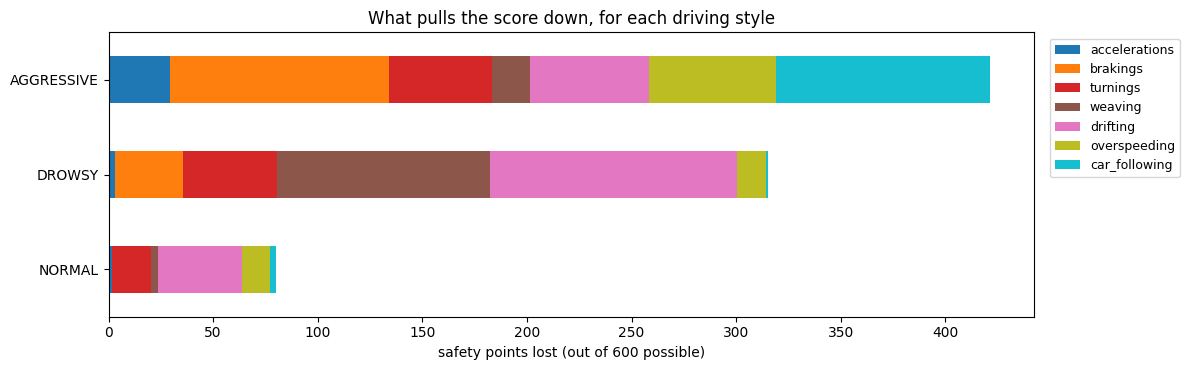

In [7]:
avg_lost = lost.assign(behavior=trips.behavior).groupby("behavior").mean().reindex(ORDER)
ax = avg_lost.plot.barh(stacked=True, figsize=(12, 3.8), colormap="tab10")
ax.set_xlabel("safety points lost (out of 600 possible)")
ax.set_ylabel("")
ax.set_title("What pulls the score down, for each driving style")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

In [8]:
trips[["driver", "behavior", "road", "safety_score", "band", "reasons"]].sort_values("safety_score").head(10)

,driver,behavior,road,safety_score,band,reasons
12,D2,AGGRESSIVE,SECONDARY,396,Risky,"car-following (-144), brakings (-140)"
8,D2,AGGRESSIVE,MOTORWAY,413,Risky,"car-following (-130), brakings (-113)"
33,D5,AGGRESSIVE,SECONDARY,449,Risky,"drifting (-115), car-following (-103)"
39,D6,AGGRESSIVE,MOTORWAY,452,Risky,"turnings (-132), brakings (-126)"
3,D1,AGGRESSIVE,MOTORWAY,454,Risky,"weaving (-162), overspeeding (-98)"
13,D2,DROWSY,SECONDARY,458,Risky,"weaving (-165), drifting (-123)"
26,D4,AGGRESSIVE,MOTORWAY,462,Risky,"brakings (-142), car-following (-119)"
29,D5,AGGRESSIVE,MOTORWAY,463,Risky,"car-following (-117), brakings (-100)"
38,D6,DROWSY,SECONDARY,497,Risky,"weaving (-160), drifting (-131)"
5,D1,AGGRESSIVE,SECONDARY,503,Risky,"overspeeding (-132), brakings (-129)"


The table shows the 10 lowest-scoring trips with their **top reasons**. This is the kind of feedback
an app could show the driver: *"Your score dropped mainly because of tailgating and hard braking."*

## 4. From trips to a driver

An insurer scores a **driver**, not a single trip. We combine a driver's trips with a
**distance-weighted average**, so a long trip counts more than a short one.

**Example:** a 16 km trip scored 800 and a 24 km trip scored 500, giving
(800 × 16 + 500 × 24) ÷ 40 = **620**. (A plain average would say 650.)

⚠️ In this dataset every driver **acted out all three styles**, so mixing all their trips would make
everyone look "average". Instead we compute the score for each driver **in each style**: what that
person's score would be if they always drove that way.

In [9]:
driver_table = (trips.groupby(["driver", "behavior"])
                .apply(lambda g: ss.driver_score(g.safety_score, g.distance_km))
                .unstack()[ORDER].round(0).astype(int))
driver_table

behavior,NORMAL,DROWSY,AGGRESSIVE
driver,,,
D1,773,582,474
D2,825,548,407
D3,827,588,538
D4,853,646,506
D5,802,637,458
D6,829,516,452


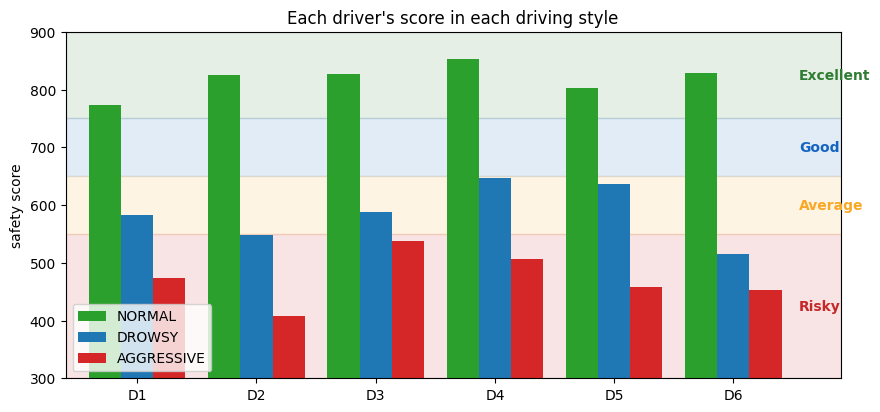

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
xs = np.arange(len(driver_table))
for lowest, name, _ in ss.BANDS:
    top = min([b[0] for b in ss.BANDS if b[0] > lowest], default=900)
    ax.axhspan(lowest, top, color=BAND_COLORS[name], alpha=0.12)
    ax.text(len(xs) - 0.45, (lowest + top) / 2, name, va="center", color=BAND_COLORS[name], weight="bold")
for i, b in enumerate(ORDER):
    ax.bar(xs + (i - 1) * 0.27, driver_table[b] - 300, bottom=300, width=0.27, color=COLORS[b], label=b)
ax.set_xticks(xs)
ax.set_xticklabels(driver_table.index)
ax.set_ylim(300, 900)
ax.set_xlim(-0.6, len(xs) - 0.1)
ax.set_ylabel("safety score")
ax.set_title("Each driver's score in each driving style")
ax.legend(loc="lower left")
plt.show()

**For every one of the 6 drivers**, the order is the same: driving normally scores **Excellent**
(773–853), and driving drowsy or aggressively drops the score by about **170–420 points**. The score
judges *how* someone drives, not *who* they are.

## 5. "What if?": a driver who is sometimes aggressive

Real drivers are not 100% safe or 100% aggressive. What happens to a driver's score when part of
their driving is aggressive? We take each driver's real normal and aggressive trips and mix them:
for example "80% of kilometres driven normally, 20% aggressively".

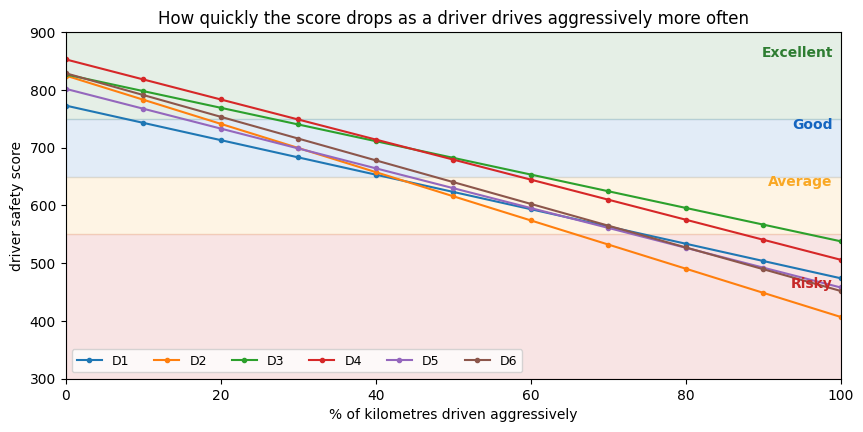

In [11]:
shares = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(10, 4.5))
for lowest, name, _ in ss.BANDS:
    top = min([b[0] for b in ss.BANDS if b[0] > lowest], default=900)
    ax.axhspan(lowest, top, color=BAND_COLORS[name], alpha=0.12)
    ax.text(99, (lowest + top) / 2 + 40, name, ha="right", va="center", color=BAND_COLORS[name], weight="bold")
for driver, row in driver_table.iterrows():
    mixed = [ss.driver_score([row.NORMAL, row.AGGRESSIVE], [1 - s, s]) for s in shares]
    ax.plot(shares * 100, mixed, marker="o", ms=3, label=driver)
ax.set_xlabel("% of kilometres driven aggressively")
ax.set_ylabel("driver safety score")
ax.set_ylim(300, 900)
ax.set_xlim(0, 100)
ax.set_title("How quickly the score drops as a driver drives aggressively more often")
ax.legend(ncol=6, loc="lower left", fontsize=9)
plt.show()

In [12]:
mix = pd.DataFrame({f"{int(s * 100)}% aggressive": [ss.driver_score([r.NORMAL, r.AGGRESSIVE], [1 - s, s])
                                                   for _, r in driver_table.iterrows()]
                    for s in [0, 0.1, 0.2, 0.3, 0.5]}, index=driver_table.index).round(0).astype(int)
mix.loc["band of the average"] = [ss.band(v)[0] for v in mix.mean()]
mix

,0% aggressive,10% aggressive,20% aggressive,30% aggressive,50% aggressive
driver,,,,,
D1,773,743,713,683,624
D2,825,783,741,700,616
D3,827,798,769,740,682
D4,853,818,784,749,680
D5,802,768,733,699,630
D6,829,791,754,716,640
band of the average,Excellent,Excellent,Good,Good,Average


Roughly, **every 10% of aggressive kilometres costs about 30–40 points**. By 20–30% aggressive
driving, most drivers have dropped from **Excellent** to **Good**, and at about half of their driving
they are down to **Average** or the bottom of **Good**.

## 6. What it means for the premium

Example: a yearly premium of **₹10,000** before the driving score is applied.

In [13]:
BASE = 10_000
rows = []
for driver, row in driver_table.iterrows():
    for b in ORDER:
        s = row[b]
        name, change = ss.band(s)
        rows.append({"driver": driver, "style": b, "safety score": s, "band": name,
                     "premium change": f"{change:+.0%}", "yearly premium (₹)": int(ss.premium(BASE, s))})
premiums = pd.DataFrame(rows)
premiums.pivot(index="driver", columns="style", values="yearly premium (₹)")[ORDER]

style,NORMAL,DROWSY,AGGRESSIVE
driver,,,
D1,8000,10000,12500
D2,8000,12500,12500
D3,8000,10000,12500
D4,8000,10000,12500
D5,8000,10000,12500
D6,8000,12500,12500


The same person pays **₹8,000** driving normally and **₹12,500** driving aggressively: a strong,
fair reason to drive safely.

## 7. Save the results

In [14]:
trips.to_csv("../results/step6_trip_safety_scores.csv", index=False)
driver_table.to_csv("../results/step6_driver_scores.csv")
print("saved", len(trips), "trip scores and", len(driver_table), "driver rows")

saved 40 trip scores and 6 driver rows


## 8. Limits of this prototype ⚠️

- **Small, acted dataset:** 40 trips, 6 drivers, styles performed on purpose. A real score would need
  many drivers over months, and should be checked against **real insurance claims**, not acted labels.
- **Band limits and discounts are examples.** They fit this data; an insurer would set them from
  claims data and regulations.
- **The scoring settings came from matching the app (Step 4)**, and the safety score was never tuned on the
  true labels, so the clean separation in section 2 is a real result, not a fitted one.
- **Context matters:** night driving, weather and road type are not in the score yet. A drowsy trip at
  night is probably riskier than the numbers show.
- **Fairness and privacy:** drivers must agree to being tracked, the data must be protected, and the
  score must be explainable (which ours is: every point lost has a reason).
- **License:** the UAH-DriveSet is CC BY-NC 4.0. This is fine for a college project but not for commercial use.

## Summary

| What | Result |
|---|---|
| Safety score | 300 + 12 × (Step 4 overall score − 50), between 300 and 900 |
| Bands | Excellent 750+, Good 650–749, Average 550–649, Risky below 550 |
| Separation | **every normal trip scores higher than every drowsy or aggressive trip** |
| Trips by band | Normal: 16 Excellent + 1 Good · Aggressive: 9 Risky + 2 Average |
| Per driver | normal driving 773–853, aggressive 407–538, for all 6 drivers |
| Explanations | every lost point is traced to one of the 7 behaviours |
| Premium example (₹10,000) | ₹8,000 when driving normally vs ₹12,500 when driving aggressively |

**This completes the project:** we implemented the paper's pipeline (Steps 1–5), matched and then beat
the original app's classification (39/40 vs 36/40), and turned it into an explainable
**driver safety score** for usage-based insurance.